# 06. Entrenamiento final del modelo IT

Este notebook realiza el entrenamiento final del modelo **CatBoost** seleccionado en la fase de optimización.

Flujo:
1. Carga de la tabla preparada.
2. Recuperación de los hiperparámetros seleccionados.
3. División temporal en entrenamiento+validación y test.
4. Entrenamiento final con las semanas 1–111.
5. Evaluación final sobre las semanas 112–131.
6. Métricas por horizonte y globales.
7. Análisis de errores y predicciones.
8. Importancia de variables.
9. Exportación de resultados y del modelo final.

El conjunto de test permanece completamente aislado durante el entrenamiento.


In [5]:
import os
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

BASE_DIR = os.getcwd()

DATA_FILE = os.path.join(BASE_DIR, "Tabla_Entrenamiento_IT_Modelado.csv")
HYPER_FILE = os.path.join(BASE_DIR, "Mejores_Hiperparametros_IT.csv")

RESULTADOS_FILE = os.path.join(BASE_DIR, "Resultados_Finales_CatBoost_IT.csv")
PREDICCIONES_FILE = os.path.join(BASE_DIR, "Predicciones_Finales_CatBoost_IT.csv")
IMPORTANCIAS_FILE = os.path.join(BASE_DIR, "Importancia_Variables_CatBoost_IT.csv")
MODELO_FILE = os.path.join(BASE_DIR, "Modelo_Final_CatBoost_IT.cbm")

print("Directorio de trabajo:", BASE_DIR)
print("Datos:", DATA_FILE)
print("Hiperparámetros:", HYPER_FILE)


Directorio de trabajo: c:\Users\Oscar\OneDrive\Documents\TFM\10 Modelado
Datos: c:\Users\Oscar\OneDrive\Documents\TFM\10 Modelado\Tabla_Entrenamiento_IT_Modelado.csv
Hiperparámetros: c:\Users\Oscar\OneDrive\Documents\TFM\10 Modelado\Mejores_Hiperparametros_IT.csv


In [6]:
# Carga de datos
df = pd.read_csv(DATA_FILE, sep=";", low_memory=False)

print("Filas:", len(df))
print("Columnas:", len(df.columns))
print("Periodo:", df["ID_Semana"].min(), "a", df["ID_Semana"].max())

TARGETS = [
    "IT_Futura_W1",
    "IT_Futura_W2",
    "IT_Futura_W3",
    "IT_Futura_W4"
]

EXCLUDED = [
    "CodEmpleado",
    "FechaInicio",
    "FechaFin",
    "IdAlta",
    "IdContrato",
    "UltimoStatus",
    "FechaInicioAlta",
    "FechaFinAlta",
    "ParticipacionDesde",
    "ParticipacionHasta",
    "Nacimiento",
    "OrganizacionDesdeAsignada",
    "OrganizacionHastaAsignada",
    "OrigenAsignacionOrganizativa",
    "ITAbierto",
    "ElegiblePrediccion"
]

FEATURES = [c for c in df.columns if c not in TARGETS + EXCLUDED]

CATEGORICAL = [
    "ClaseContrato",
    "FamiliaFuncion",
    "Centro",
    "UnidadOrganizativa",
    "Funcion",
    "Area",
    "Servicio",
    "Sexo",
    "TipoJornada"
]

NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

print("Predictores:", len(FEATURES))
print("Categóricas:", len(CATEGORICAL))
print("Numéricas:", len(NUMERIC))
print("Targets:", TARGETS)


Filas: 1755108
Columnas: 40
Periodo: 1 a 131
Predictores: 36
Categóricas: 9
Numéricas: 27
Targets: ['IT_Futura_W1', 'IT_Futura_W2', 'IT_Futura_W3', 'IT_Futura_W4']


In [7]:
# Verificación de variables
faltantes = [c for c in FEATURES + TARGETS if c not in df.columns]
if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {faltantes}")

# CatBoost necesita que las categóricas no tengan NaN.
# La tabla preparada ya contiene imputación, pero se verifica igualmente.
for c in CATEGORICAL:
    df[c] = df[c].fillna(df[c].mode(dropna=True).iloc[0]).astype(str)

for c in NUMERIC:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mean())

for c in TARGETS:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Nulos en predictores:", int(df[FEATURES].isna().sum().sum()))
print("Nulos en targets:", int(df[TARGETS].isna().sum().sum()))


Nulos en predictores: 0
Nulos en targets: 0


In [8]:
# Recuperar los mejores hiperparámetros de la optimización
hyper = pd.read_csv(HYPER_FILE, sep=";")

print(hyper.to_string(index=False))

# Buscar la fila correspondiente a CatBoost.
fila_cb = hyper[hyper["Modelo"].astype(str).str.lower().eq("catboost")]

if fila_cb.empty:
    raise ValueError("No se encontró CatBoost en Mejores_Hiperparametros_IT.csv")

fila_cb = fila_cb.iloc[0]

def valor_hyper(nombre, default=None):
    if nombre not in fila_cb.index:
        return default
    v = fila_cb[nombre]
    if pd.isna(v):
        return default
    try:
        return int(float(v))
    except:
        try:
            return float(v)
        except:
            return v

cat_params = {
    "depth": valor_hyper("depth", 6),
    "learning_rate": valor_hyper("learning_rate", 0.02),
    "iterations": valor_hyper("iterations", 500),
    "l2_leaf_reg": valor_hyper("l2_leaf_reg", 7),
    "random_strength": valor_hyper("random_strength", 0),
}

print("\nHiperparámetros utilizados:")
for k, v in cat_params.items():
    print(f"  {k}: {v}")


           Modelo  Trial  MAE_Promedio  RMSE_Promedio  R2_Promedio  Tiempo_entrenamiento_s                                                                                                                                                                                                                                                                  Hiperparametros Modo
         CatBoost      1      0.227930       0.723924     0.610906               45.176485                                                                                                                                                                                   {"random_strength": 0, "learning_rate": 0.02, "l2_leaf_reg": 7, "iterations": 500, "depth": 6}  GPU
Gradient Boosting      2      0.235416       0.724402     0.610365             2682.168955                                                                                 {"model__estimator__subsample": 0.7, "model__estimator__n_estimators": 300, "model__estimat

In [10]:
# División temporal definitiva
# Train + Validation: semanas 1–111
# Test: semanas 112–131

TRAIN_VAL_MAX_WEEK = 111
TEST_MIN_WEEK = 112

train_val = df[df["ID_Semana"] <= TRAIN_VAL_MAX_WEEK].copy()
test = df[df["ID_Semana"] >= TEST_MIN_WEEK].copy()

if train_val.empty or test.empty:
    raise ValueError("La división temporal produjo un conjunto vacío.")

X_train_val = train_val[FEATURES].copy()
Y_train_val = train_val[TARGETS].copy()

X_test = test[FEATURES].copy()
Y_test = test[TARGETS].copy()

print("TRAIN + VALIDACIÓN")
print("Semanas:", train_val["ID_Semana"].min(), "a", train_val["ID_Semana"].max())
print("Filas:", len(train_val))

print("\nTEST")
print("Semanas:", test["ID_Semana"].min(), "a", test["ID_Semana"].max())
print("Filas:", len(test))


TRAIN + VALIDACIÓN
Semanas: 1 a 111
Filas: 1479453

TEST
Semanas: 112 a 131
Filas: 275655


In [11]:
# Índices de variables categóricas para CatBoost
cat_indices = [FEATURES.index(c) for c in CATEGORICAL]

# CatBoost admite múltiples objetivos mediante MultiRMSE.
modelo_final = CatBoostRegressor(
    loss_function="MultiRMSE",
    eval_metric="MultiRMSE",
    **cat_params,
    verbose=False,
    random_seed=42,
    allow_writing_files=False,
    task_type="CPU"
)

print("Modelo final configurado.")
print("Objetivos:", len(TARGETS))
print("Variables categóricas:", len(cat_indices))


Modelo final configurado.
Objetivos: 4
Variables categóricas: 9


In [12]:
# Entrenamiento final
print("Iniciando entrenamiento final de CatBoost...")
inicio = time.time()

modelo_final.fit(
    X_train_val,
    Y_train_val,
    cat_features=cat_indices,
    verbose=False
)

tiempo_entrenamiento = time.time() - inicio

print(f"Entrenamiento finalizado en {tiempo_entrenamiento/60:.2f} minutos.")


Iniciando entrenamiento final de CatBoost...
Entrenamiento finalizado en 25.29 minutos.


In [13]:
# Predicción sobre TEST
inicio_pred = time.time()

pred_test = modelo_final.predict(
    X_test
)

tiempo_prediccion = time.time() - inicio_pred

pred_test = np.asarray(pred_test)

if pred_test.ndim == 1:
    pred_test = pred_test.reshape(-1, len(TARGETS))

print(f"Predicción completada en {tiempo_prediccion:.2f} segundos.")
print("Shape predicciones:", pred_test.shape)


Predicción completada en 1.10 segundos.
Shape predicciones: (275655, 4)


In [14]:
# Métricas finales por horizonte
resultados = []

for i, target in enumerate(TARGETS):
    y_true = Y_test[target].to_numpy()
    y_pred = pred_test[:, i]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    resultados.append({
        "Horizonte": target,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

resultados_df = pd.DataFrame(resultados)

# Promedio de las métricas de los cuatro horizontes
resultados_df.loc[len(resultados_df)] = {
    "Horizonte": "Promedio",
    "MAE": resultados_df["MAE"].mean(),
    "RMSE": resultados_df["RMSE"].mean(),
    "R2": resultados_df["R2"].mean()
}

print(resultados_df.to_string(index=False))


   Horizonte      MAE     RMSE       R2
IT_Futura_W1 0.169354 0.605231 0.737948
IT_Futura_W2 0.216525 0.696908 0.650659
IT_Futura_W3 0.253020 0.760042 0.582371
IT_Futura_W4 0.281547 0.804456 0.528661
    Promedio 0.230111 0.716659 0.624910


In [16]:
# Predicciones y errores

predicciones_df = test[
    ["ID_Semana", "AnioISO", "SemanaISO"] + TARGETS
].copy()

for i, target in enumerate(TARGETS):
    pred_col = target + "_Pred"
    error_col = target + "_Error"

    predicciones_df[pred_col] = pred_test[:, i]
    predicciones_df[error_col] = (
        predicciones_df[target] - predicciones_df[pred_col]
    )

print(predicciones_df.head())


         ID_Semana  AnioISO  SemanaISO  IT_Futura_W1  IT_Futura_W2  \
1479453        112     2026          8             5             5   
1479454        112     2026          8             0             0   
1479455        112     2026          8             0             0   
1479456        112     2026          8             0             0   
1479457        112     2026          8             0             0   

         IT_Futura_W3  IT_Futura_W4  IT_Futura_W1_Pred  IT_Futura_W1_Error  \
1479453             5             0           4.345840            0.654160   
1479454             0             0           0.025587           -0.025587   
1479455             0             0           0.030490           -0.030490   
1479456             0             0           0.038978           -0.038978   
1479457             0             0           0.037849           -0.037849   

         IT_Futura_W2_Pred  IT_Futura_W2_Error  IT_Futura_W3_Pred  \
1479453           4.020396            0.9

In [18]:
# Importancia de variables
importancias = modelo_final.get_feature_importance(
    type="FeatureImportance"
)

importancia_df = pd.DataFrame({
    "Variable": FEATURES,
    "Importancia": importancias
}).sort_values("Importancia", ascending=False)

importancia_df["Importancia_%"] = (
    importancia_df["Importancia"] /
    importancia_df["Importancia"].sum() * 100
)

print("Top 20 variables:")
print(importancia_df.head(20).to_string(index=False))


Top 20 variables:
                   Variable  Importancia  Importancia_%
    Previous1WeekITLongTerm    43.635069      43.635069
            Previous1WeekIT    12.771496      12.771496
   Previous2WeeksITLongTerm     5.510906       5.510906
         Previous12MonthsIT     5.422933       5.422933
 Previous12MonthsITLongTerm     3.806392       3.806392
   Previous1MonthITLongTerm     2.982305       2.982305
         UnidadOrganizativa     2.700943       2.700943
                       Edad     2.657581       2.657581
Previous12MonthsITShortTerm     2.421721       2.421721
          Previous6MonthsIT     1.835891       1.835891
                  SemanaISO     1.409448       1.409448
           Previous2WeeksIT     1.320169       1.320169
                       Area     1.236947       1.236947
              ClaseContrato     1.167886       1.167886
             FamiliaFuncion     1.085880       1.085880
  Previous6MonthsITLongTerm     1.075160       1.075160
   DiasTrabajadosHastaCorte   

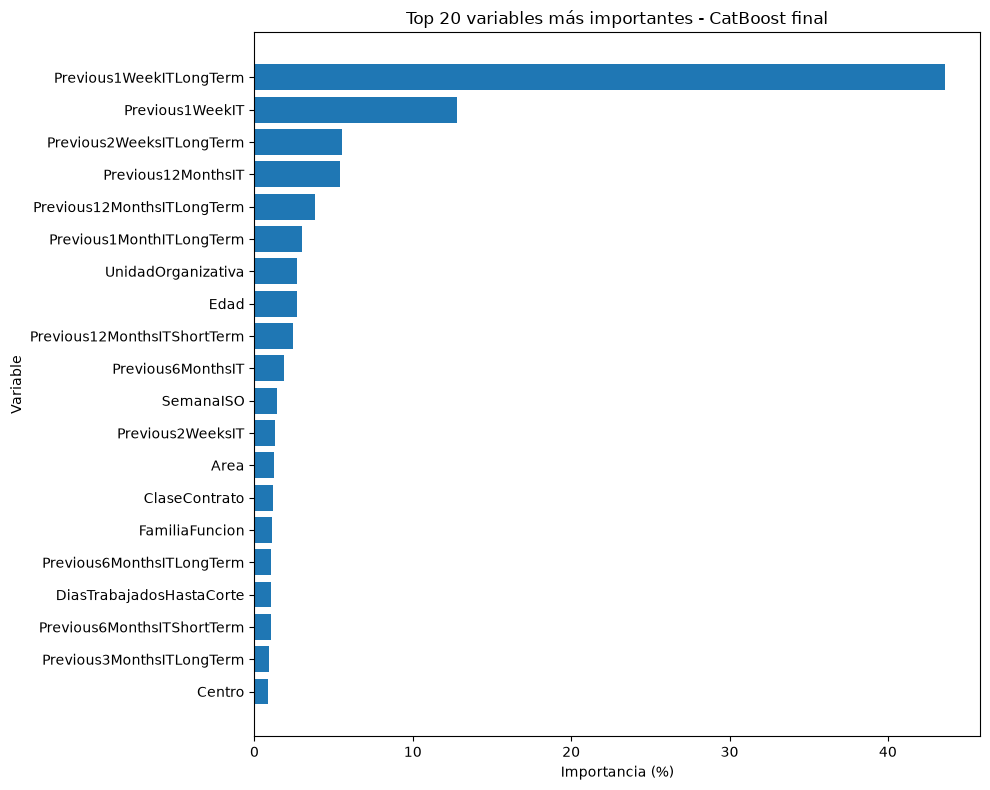

In [19]:
# Visualización de las 20 variables más importantes
top20 = importancia_df.head(20).sort_values("Importancia_%")

plt.figure(figsize=(10, 8))
plt.barh(top20["Variable"], top20["Importancia_%"])
plt.xlabel("Importancia (%)")
plt.ylabel("Variable")
plt.title("Top 20 variables más importantes - CatBoost final")
plt.tight_layout()
plt.show()


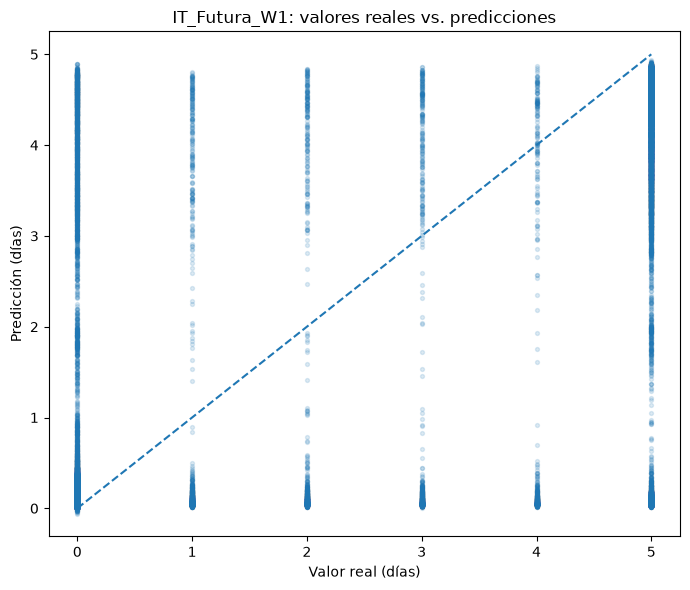

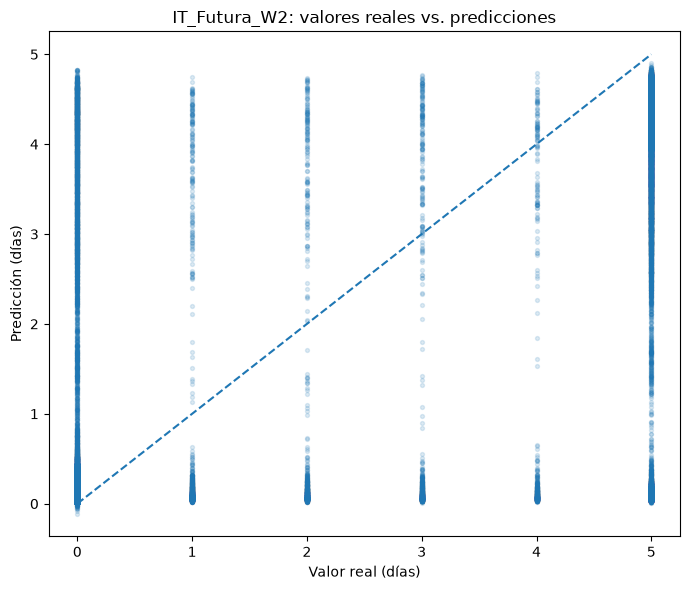

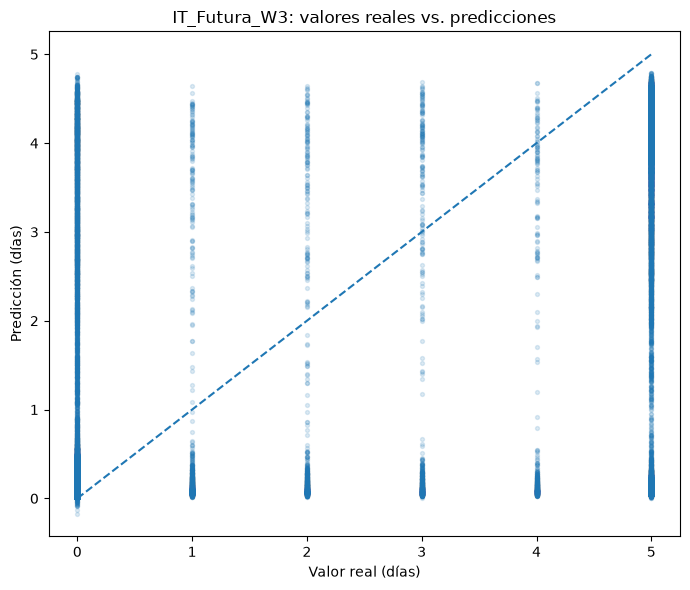

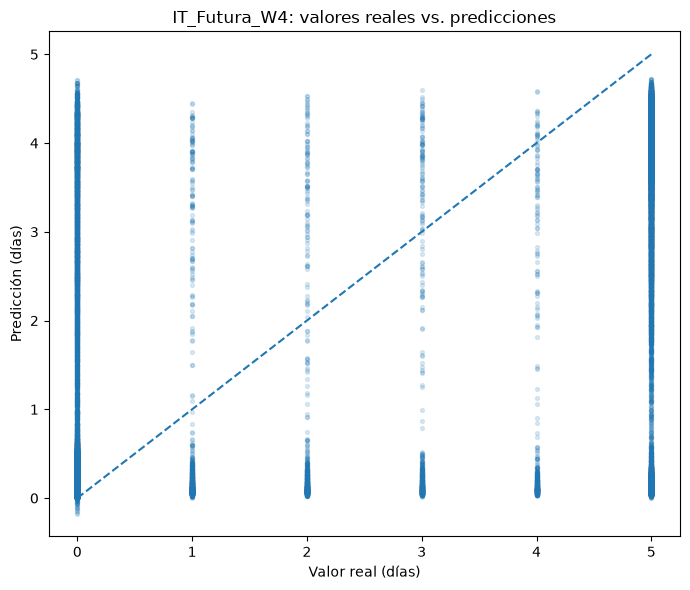

In [20]:
# Distribución de predicciones frente a valores reales por horizonte
for target in TARGETS:
    pred_col = target + "_Pred"

    plt.figure(figsize=(7, 6))
    plt.scatter(
        predicciones_df[target],
        predicciones_df[pred_col],
        alpha=0.15,
        s=8
    )

    max_val = max(
        predicciones_df[target].max(),
        predicciones_df[pred_col].max()
    )

    plt.plot([0, max_val], [0, max_val], linestyle="--")
    plt.xlabel("Valor real (días)")
    plt.ylabel("Predicción (días)")
    plt.title(f"{target}: valores reales vs. predicciones")
    plt.tight_layout()
    plt.show()


In [21]:
# Guardado de resultados
resultados_df.to_csv(RESULTADOS_FILE, sep=";", index=False, decimal=",")
predicciones_df.to_csv(PREDICCIONES_FILE, sep=";", index=False, decimal=",")
importancia_df.to_csv(IMPORTANCIAS_FILE, sep=";", index=False, decimal=",")

modelo_final.save_model(MODELO_FILE)

resumen = {
    "modelo": "CatBoost",
    "train_val_semanas": [1, 111],
    "test_semanas": [112, 131],
    "filas_train_val": int(len(train_val)),
    "filas_test": int(len(test)),
    "numero_predictores": int(len(FEATURES)),
    "numero_categoricas": int(len(CATEGORICAL)),
    "numero_numericas": int(len(NUMERIC)),
    "tiempo_entrenamiento_segundos": float(tiempo_entrenamiento),
    "tiempo_prediccion_segundos": float(tiempo_prediccion),
    "hiperparametros": {k: (int(v) if isinstance(v, (np.integer,)) else float(v) if isinstance(v, (np.floating,)) else v)
                        for k, v in cat_params.items()}
}

with open(os.path.join(BASE_DIR, "Resumen_Entrenamiento_Final_CatBoost_IT.json"), "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)

print("Archivos guardados:")
print("-", RESULTADOS_FILE)
print("-", PREDICCIONES_FILE)
print("-", IMPORTANCIAS_FILE)
print("-", MODELO_FILE)


Archivos guardados:
- c:\Users\Oscar\OneDrive\Documents\TFM\10 Modelado\Resultados_Finales_CatBoost_IT.csv
- c:\Users\Oscar\OneDrive\Documents\TFM\10 Modelado\Predicciones_Finales_CatBoost_IT.csv
- c:\Users\Oscar\OneDrive\Documents\TFM\10 Modelado\Importancia_Variables_CatBoost_IT.csv
- c:\Users\Oscar\OneDrive\Documents\TFM\10 Modelado\Modelo_Final_CatBoost_IT.cbm


In [22]:
# Verificación final
print("========== VERIFICACIÓN FINAL ==========")
print("Modelo:", "CatBoost")
print("Train + Validation:", len(train_val), "filas | semanas 1–111")
print("Test:", len(test), "filas | semanas 112–131")
print("Predictores:", len(FEATURES))
print("Targets:", len(TARGETS))
print("Tiempo entrenamiento:", f"{tiempo_entrenamiento/60:.2f} min")
print("Tiempo predicción:", f"{tiempo_prediccion:.2f} s")
print("\nMétricas finales:")
print(resultados_df.to_string(index=False))
print("\nEntrenamiento final completado correctamente.")


========== VERIFICACIÓN FINAL ==========
Modelo: CatBoost
Train + Validation: 1479453 filas | semanas 1–111
Test: 275655 filas | semanas 112–131
Predictores: 36
Targets: 4
Tiempo entrenamiento: 25.29 min
Tiempo predicción: 1.10 s

Métricas finales:
   Horizonte      MAE     RMSE       R2
IT_Futura_W1 0.169354 0.605231 0.737948
IT_Futura_W2 0.216525 0.696908 0.650659
IT_Futura_W3 0.253020 0.760042 0.582371
IT_Futura_W4 0.281547 0.804456 0.528661
    Promedio 0.230111 0.716659 0.624910

Entrenamiento final completado correctamente.
